# Lesson 3. A Gaussian on a Plane: From a Bell Curve to a Spot

[Course plan](../../README.md) · [Lesson 2](lesson-02.ipynb) · [Русский](../ru/lesson-03.ipynb) · [Next lesson](lesson-04.ipynb)

In the previous lesson, we moved along a ruler and calculated a weight at each point. An image needs more than one ruler: we can move right, or we can move up. We'll add a second coordinate and see how the familiar bell curve becomes a soft spot.

We'll start with three pictures of the same function. Then we'll pick one point and calculate its weight in two ways. The operations are familiar: subtract, divide, square, and take an exponential. The new part is how we combine the two directions.

## 1. One Spot in Three Pictures

On the left, weight is shown as color: dark areas are weak, bright areas are strong. In the middle, the same weight is drawn as height, making a hill. On the right, lines join points with equal weight. **The hill's height is the function's value, not a third coordinate of an object.** We're still working on a plane.

The cross marks the point where we're reading the weight. A small plus marks the spot's center. The calculation for the selected point appears beneath the plots; we'll work through each row shortly.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
from IPython.display import display

course_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "plane_demos.py").is_file()),
    None,
)
if course_root is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from plane_demos import plane_figure, plane_lab, slices_figure, ellipse_figure
LANG = "en"

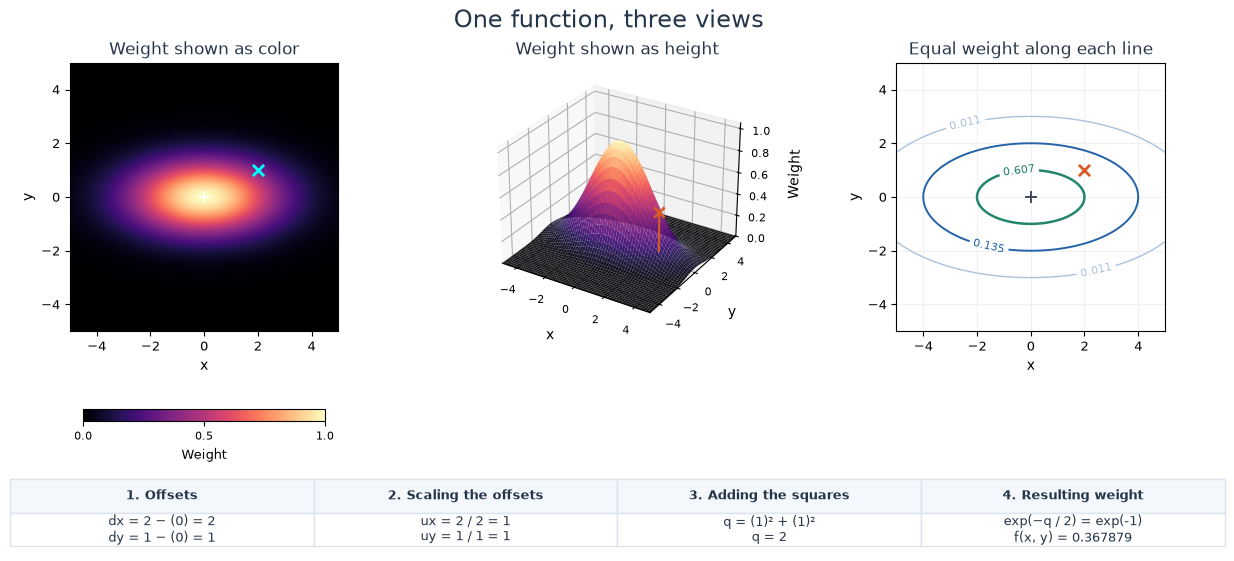

In [2]:
display(plane_figure(language=LANG))
display(plane_lab(language=LANG))

Four parameter changes reveal different parts of the picture:

1. In the **“Circle”** example, the two scales are equal, so the spot spreads out equally in all directions.
2. In the starting example, the scale along $x$ is 2, and along $y$ it is 1. The contours stretch to the left and right. The peak stays at height 1.
3. We move the center's $y$ coordinate from 0 to 1. The spot moves up. The cross stays where it was, so the weight under it changes.
4. After a reset, we change only “Point: x” and “Point: y.” The spot now stays in place; only the location where we sample it changes.

All three views use the same coordinate range, from −5 to 5. The weight scale stays between 0 and 1, and the color scale stays fixed too. An expanding spot therefore cannot hide behind an automatic change in the plot's scale.

The calculations below use the starting example: center $(0,0)$, scales 2 and 1, point $(2,1)$.

## 2. Two Coordinates Instead of One

The pair $(2,1)$ has an order: first $x=2$, then $y=1$. From the origin, we move two units right and one unit up. Positive $y$ points upward in this lesson. Image arrays often count rows downward from the top; we'll return to that different convention when we work with pixels.

The center now has two numbers too: $(\mu_x,\mu_y)$. The small letters below are called **subscripts**. Here they only name the direction: $\mu_x$ is “mu along x,” and $\mu_y$ is “mu along y.” They do not mean multiplication by $x$ or $y$.

| Notation | How to read it | Our values |
|---|---|---|
| $(x,y)$ | Point coordinates | $(2,1)$ |
| $(\mu_x,\mu_y)$ | Center coordinates | $(0,0)$ |
| $\sigma_x$ | “sigma x,” the horizontal width scale | 2 |
| $\sigma_y$ | “sigma y,” the vertical width scale | 1 |
| $f(x,y)$ | “f of x and y,” the weight at this point | Not calculated yet |

The function takes two numbers and returns **one**. Both the map's color and the hill's height show that one number.

We'll measure the point, center, and scales in the same units, such as centimeters. The demo uses arbitrary units. Both scales must be greater than zero. For now, the width directions line up with the $x$ and $y$ axes; we'll rotate the spot in the next lesson.

## 3. One Bell Curve for Each Direction

For now, we set the vertical direction aside. Horizontally, everything works just as in lesson 2:

$$
d_x=x-\mu_x=2-0=2,
\qquad u_x=\frac{d_x}{\sigma_x}=\frac{2}{2}=1.
$$

$d_x$ is the horizontal offset. $u_x$ is the same offset measured in scale units. Two centimeters with a two-centimeter scale means one scale unit. Next come the square, division by 2, minus sign, and exponential:

$$
w_x=\exp\left(-\frac{u_x^2}{2}\right)
=\exp\left(-\frac{1\cdot1}{2}\right)
=\exp(-0.5)\approx0.606531.
$$

$w_x$ is a short name for the weight based **only on the horizontal direction**. Now we repeat the calculation vertically:

$$
d_y=y-\mu_y=1-0=1,
\qquad u_y=\frac{d_y}{\sigma_y}=\frac{1}{1}=1.
$$

$$
w_y=\exp\left(-\frac{u_y^2}{2}\right)
=\exp\left(-\frac{1\cdot1}{2}\right)
=\exp(-0.5)\approx0.606531.
$$

We moved two coordinate units horizontally and one vertically, but the offsets **in scale units** are the same. That's why the two weights match.

For our spot, we multiply them:

$$
f(x,y)=w_x\cdot w_y.
$$

Moving away along either direction now reduces the combined weight. If we're exactly at the center along one axis, its weight is 1, so multiplication leaves the other axis's weight unchanged. If we move away along both axes, the two reductions act together.

At $(2,1)$, this gives approximately $0.606531\cdot0.606531\approx0.367879$. We won't multiply already rounded numbers in the calculation. Python will retain its full precision, and we'll use six decimal places only when printing.

In [3]:
ux = (2 - 0) / 2
uy = (1 - 0) / 1
weight_x = math.exp(-(ux * ux) / 2)
weight_y = math.exp(-(uy * uy) / 2)
print(f"wx = {weight_x:.6f}")
print(f"wy = {weight_y:.6f}")
print(f"wx * wy = {weight_x * weight_y:.6f}")

wx = 0.606531
wy = 0.606531
wx * wy = 0.367879


## 4. Why a Sum Appears Inside the Formula

We multiplied two weights, yet the compact formula will contain an addition. The calculation hasn't changed. When powers with the same base are multiplied, **their exponents add**.

For whole-number exponents, we can count the factors:

$$
2^2\cdot2^3=(2\cdot2)\cdot(2\cdot2\cdot2)=2^5=2^{2+3}.
$$

Fractional and negative powers follow the same rule. For example, $e^{-0.5}=1/\sqrt{e}$, so:

$$
e^{-0.5}\cdot e^{-0.5}
=\frac{1}{\sqrt{e}}\cdot\frac{1}{\sqrt{e}}
=\frac{1}{e}=e^{-1}.
$$

The two exponents, each $-0.5$, add to $-1$. In general, the rule is $e^a\cdot e^b=e^{a+b}$. Here, $a$ and $b$ stand for any two exponents.

We substitute our expressions for them. We can follow the whole change one line at a time:

$$
\begin{aligned}
f(x,y)&=\exp\left(-\frac{u_x^2}{2}\right)\cdot\exp\left(-\frac{u_y^2}{2}\right)\\
&=\exp\left(-\frac{u_x^2}{2}-\frac{u_y^2}{2}\right)\\
&=\exp\left(-\frac{u_x^2+u_y^2}{2}\right).
\end{aligned}
$$

In the last line, both fractions have the same denominator, 2. We add their numerators and keep the common division. We are adding **squared offsets inside the exponent**, not adding the finished weights outside it.

## 5. Building the Formula from the Inside

Now we replace $u_x$ and $u_y$ with the operations they stand for:

$$
f(x,y)=\exp\left[-\frac12\left(
\left(\frac{x-\mu_x}{\sigma_x}\right)^2+
\left(\frac{y-\mu_y}{\sigma_y}\right)^2
\right)\right].
$$

The square brackets work just like round parentheses here: they group the expression passed to the exponential. The two fractions describe the two directions. Each small superscript 2 applies to **the whole fraction**, including its denominator.

The calculation follows this order:

1. We subtract the center separately from $x$ and $y$.
2. We divide each offset by the scale for **its own** direction.
3. We square both resulting numbers.
4. We add the two squares.
5. We divide the sum by 2, put a minus sign in front, and evaluate the exponential.

Calling the sum of squares $q$ gives us a name for the intermediate value:

$$
q=u_x^2+u_y^2,
\qquad f(x,y)=\exp(-q/2).
$$

$u_x$ and $u_y$ are dimensionless: centimeters canceled when divided by centimeters. Their squares, the sum $q$, the exponent $-q/2$, and the final weight have no units of length either.

At the center, both offsets are zero. Then $q=0^2+0^2=0$ and $f(\mu_x,\mu_y)=e^0=1$. Moving in any direction makes at least one square positive. The exponent becomes negative, and the weight becomes less than 1. Changing the scales still preserves the peak of 1.

## 6. Working Through the Point $(2,1)$ Without Skipping Steps

The center is $(0,0)$, with scales $\sigma_x=2$ and $\sigma_y=1$. Both coordinates and scales use the same units.

| Step | Horizontal direction | Vertical direction |
|---|---|---|
| Subtracting the center | $d_x=2-0=2$ | $d_y=1-0=1$ |
| Dividing by the corresponding scale | $u_x=2/2=1$ | $u_y=1/1=1$ |
| Squaring | $u_x^2=1\cdot1=1$ | $u_y^2=1\cdot1=1$ |

Now the two branches join:

$$
q=1+1=2,\qquad -q/2=-2/2=-1,
\qquad f(2,1)=e^{-1}\approx0.367879.
$$

On the heatmap, this number determines the color under the cross. On the hill, it is the marked point's height. In the contour view, the point lies between the lines for weights of approximately 0.607 and 0.135.

Each operation gets a separate Python line. `qx` and `qy` hold the squares, `exponent` holds the exponent, and `weight` holds the final weight. Here, `*` means multiplication, `/` means division, and `=` stores the expression on the right in the variable on the left.

In [4]:
x, y = 2.0, 1.0
mux, muy = 0.0, 0.0
sx, sy = 2.0, 1.0

dx = x - mux
dy = y - muy
ux = dx / sx
uy = dy / sy
qx = ux * ux
qy = uy * uy
q = qx + qy
exponent = -q / 2
weight = math.exp(exponent)

print(f"dx = {dx:.1f}, dy = {dy:.1f}")
print(f"ux = {ux:.1f}, uy = {uy:.1f}")
print(f"qx = {qx:.1f}, qy = {qy:.1f}")
print(f"q = {q:.1f}, exponent = {exponent:.1f}")
print(f"weight = {weight:.6f}")

dx = 2.0, dy = 1.0
ux = 1.0, uy = 1.0
qx = 1.0, qy = 1.0
q = 2.0, exponent = -1.0
weight = 0.367879


## 7. From a Circle to an Ellipse

The first figure's right-hand panel contains lines of equal weight. We take the one where the weight equals $e^{-1/2}\approx0.606531$. We already know that this weight occurs when $q=1$. The points on our chosen curve therefore satisfy:

$$
\left(\frac{x-\mu_x}{\sigma_x}\right)^2+
\left(\frac{y-\mu_y}{\sigma_y}\right)^2=1.
$$

A **contour** is a line of equal values. Crossing it does not turn off the Gaussian: the weight keeps decreasing beyond it.

When both scales equal 1 and the center is at the origin, the condition becomes $x^2+y^2=1$. This is a circle of radius 1. The connection to distance comes from the Pythagorean theorem: the square of a right triangle's diagonal side equals the sum of the squares of its other two sides. For example, moving 3 units right and 4 units up gives $3^2+4^2=9+16=25$, so the distance from the origin is $\sqrt{25}=5$. A constant sum $x^2+y^2$ therefore means a constant distance from the origin.

Now we stretch the horizontal direction by a factor of two: $\sigma_x=2$, $\sigma_y=1$. After division, the point $(2,0)$ becomes $(1,0)$, while $(0,1)$ remains $(0,1)$. Both have a sum of squared scaled coordinates equal to 1. In the original coordinates, the circle has become an **ellipse**.

For this contour, the distance from the center to the rightmost point is $\sigma_x$, and to the topmost point it is $\sigma_y$. These segments are called **semiaxes**. The contour's full horizontal width is $2\sigma_x$, and its full vertical height is $2\sigma_y$. These are the dimensions of one particular level curve; the entire soft spot still has no finite boundary.

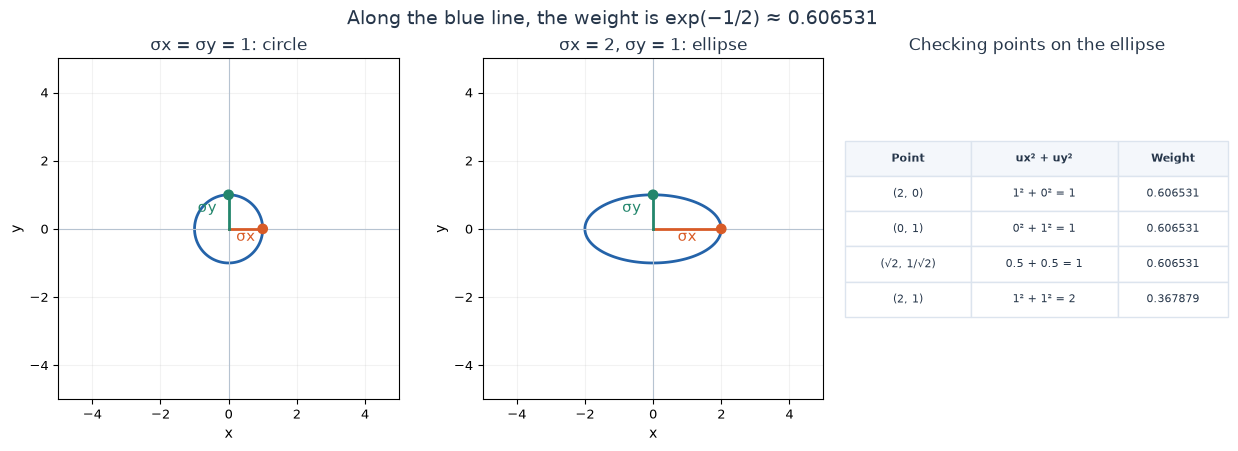

In [5]:
display(ellipse_figure(language=LANG))

We can check a point between the axis endpoints too. For the ellipse, the figure's table uses $(\sqrt{2},1/\sqrt{2})$, approximately $(1.414214,0.707107)$.

For this point:

$$
u_x=\frac{\sqrt{2}}{2}=\frac{1}{\sqrt{2}},
\qquad u_y=\frac{1/\sqrt{2}}{1}=\frac{1}{\sqrt{2}}.
$$

We can check the first equality by multiplying both sides by $\sqrt{2}$: the left becomes $\sqrt{2}\cdot\sqrt{2}/2=2/2=1$, and the right becomes 1 too. Squaring each number gives $1/2$:

$$
q=\left(\frac{1}{\sqrt{2}}\right)^2+
\left(\frac{1}{\sqrt{2}}\right)^2
=\frac12+\frac12=1.
$$

The weight is again $e^{-1/2}\approx0.606531$, so the point lies on the same contour.

By contrast, $(2,1)$ gives $1^2+1^2=2$, for a weight of about 0.367879. Moving one scale unit along **both** axes takes us farther from the center than moving one scale unit along just one axis. The corner of a rectangle with half-width 2 and half-height 1 lies outside the ellipse.

The value 0.606531 means roughly 61% **of the peak weight**. It does not mean that the ellipse contains 61% of an area or a probability.

## 8. A Slice Through the Spot Reveals the Familiar Bell Curve

We can draw a horizontal line on the heatmap and move only along it. Then $y$ stays fixed while $x$ changes. This is a **slice** of the function: we're examining the plane along one chosen line.

If the line passes through the center, $y=\mu_y$, then the vertical offset is zero, $u_y=0$, and $w_y=e^0=1$. That gives:

$$
f(x,\mu_y)=w_x\cdot1=w_x.
$$

This is exactly the one-dimensional Gaussian from the previous lesson. Its center along $x$ is $\mu_x$, its scale is $\sigma_x$, and its peak is 1.

But a slice does not have to pass through the peak. We fix $y=1$, with $\mu_y=0$ and $\sigma_y=1$. Then $u_y=(1-0)/1=1$, so $w_y=e^{-1/2}\approx0.606531$ at **every** point on this horizontal line. It simply multiplies the whole horizontal bell curve:

$$
f(x,1)=w_x\cdot0.606531\ldots
$$

Its peak is now about 0.606531, even though the complete two-dimensional function still peaks at 1. That peak remains at $(0,0)$, outside the chosen line. The slice's width along $x$ has not changed.

The vertical slice works the same way. With $x=2$ fixed, the horizontal weight $w_x\approx0.606531$ multiplies the vertical bell curve. Both slices cross at $(2,1)$, so they must give the same weight there: approximately 0.367879.

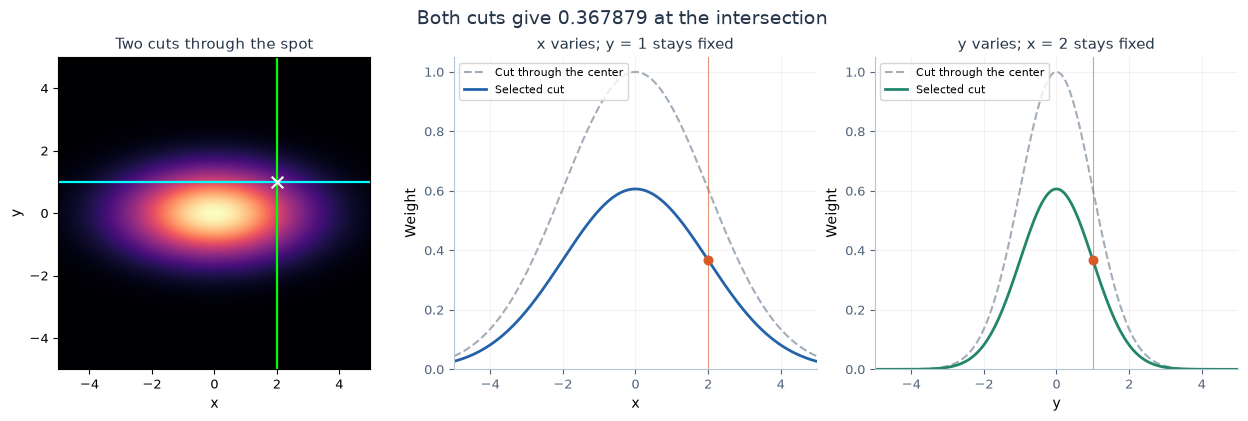

In [6]:
display(slices_figure(mux=0, muy=0, sx=2, sy=1, x=2, y=1, language=LANG))

## 9. How One Number Changes the Weight

We return to point $(2,1)$, center $(0,0)$, and scales 2 and 1. Before any changes, the weight is approximately 0.367879.

**We narrow only the horizontal scale to $\sigma_x=1$.** The offsets are still $d_x=2$ and $d_y=1$. But now $u_x=2/1=2$, while $u_y=1/1=1$. Then $q=2^2+1^2=4+1=5$, the exponent is $-5/2=-2.5$, and the weight is $e^{-2.5}\approx0.082085$. The point is farther away in units of the new horizontal scale.

**We restore $\sigma_x=2$ and widen the vertical scale to $\sigma_y=2$.** We get $u_x=2/2=1$ and $u_y=1/2=0.5$. The squares, 1 and 0.25, give $q=1.25$, the exponent is $-1.25/2=-0.625$, and the weight is $e^{-0.625}\approx0.535261$. Vertically, the same point is now closer in scale units, so the combined weight increases.

**We restore scales 2 and 1, then move the center to $(1,-1)$.** At the original point $(2,1)$, the offsets become $d_x=2-1=1$ and $d_y=1-(-1)=2$. Thus $u_x=1/2=0.5$, $u_y=2/1=2$, the sum is $q=0.25+4=4.25$, the exponent is $-2.125$, and the weight is approximately 0.119433.

If we move the point by the same offset $(1,-1)$ as the center, it ends up at $(3,0)$. The differences return to $3-1=2$ and $0-(-1)=1$, so the weight returns to 0.367879. What matters is the offset **from the center**, not where the whole arrangement sits relative to the origin.

## 10. A Function for Any Point

We can put the calculation into a function. It takes two point coordinates, two center coordinates, and two scales. All six numbers must be finite, and both scales must be positive.

The `math.isfinite` check rejects infinity and `NaN`, a special value meaning “not a number.” `all` checks that the condition holds for each of the six values. The remaining lines repeat the operations we've already worked out by hand.

In [7]:
def plane_weight(x, y, mux, muy, sx, sy):
    if not all(math.isfinite(v) for v in (x, y, mux, muy, sx, sy)):
        raise ValueError("Use finite coordinates and scales.")
    if sx <= 0 or sy <= 0:
        raise ValueError("Both scales must be greater than zero.")

    dx = x - mux
    dy = y - muy
    ux = dx / sx
    uy = dy / sy
    qx = ux * ux
    qy = uy * uy
    q = qx + qy
    return math.exp(-q / 2)


for x, y in [(0, 0), (2, 0), (0, 1), (2, 1), (-2, -1)]:
    weight = plane_weight(x, y, mux=0, muy=0, sx=2, sy=1)
    print(f"({x:2}, {y:2}) -> {weight:.6f}")

( 0,  0) -> 1.000000
( 2,  0) -> 0.606531
( 0,  1) -> 0.606531
( 2,  1) -> 0.367879
(-2, -1) -> 0.367879


The demo gives the same numbers. The final point, $(-2,-1)$, is the reflection of $(2,1)$ through the center. The offsets change sign, but their squares match, so the weights match too.

A zero scale produces a `ValueError`: we cannot divide by zero. The call `plane_weight(2, 1, 0, 0, 0, 1)` demonstrates the check: it returns an error message instead of a weight. With a positive scale, the calculation works again.

The screen shows only the square from −5 to 5. The Gaussian itself does not end at that square's edge. Beyond three scale units, for example, the weight is small but mathematically still positive. A computer may round extremely small results down to zero, as we saw in the previous lesson.

For now, we're defining a spatial weight with a peak of 1. Color, opacity, and overlapping spots arrive in lesson 5. No training takes place here: we're changing every parameter ourselves.

## 11. A Few Checks Before Looking at the Slider

The questions use center $(0,0)$ and scales $\sigma_x=2$, $\sigma_y=1$ unless stated otherwise. Each experiment starts with a prediction, followed by a calculation and a comparison with the figure.

### 1. Two Different Points, One Weight

Do points $(2,0)$ and $(0,1)$ have the same weight, or is one greater?

<details>
<summary>Worked answer</summary>

At the first point, $u_x=2/2=1$ and $u_y=0/1=0$, so $q=1^2+0^2=1$. At the second, $u_x=0/2=0$ and $u_y=1/1=1$, so $q=0^2+1^2=1$. Both give exponent $-1/2=-0.5$ and weight $e^{-0.5}\approx0.606531$. The coordinate distances differ, but each direction's scale accounts for that.

</details>

### 2. At the Corner

Both previous points lie on the 0.606531 contour. Will $(2,1)$ lie on it too?

<details>
<summary>Worked answer</summary>

At $(2,1)$, $u_x=1$ and $u_y=1$, so $q=1+1=2$. The exponent is $-2/2=-1$, and the weight is $e^{-1}\approx0.367879$. This point lies outside the chosen contour. Both departures from the center count together.

</details>

### 3. Moving Everything Together

The center moves to $(1,-1)$ and the point to $(3,0)$. The scales stay the same. Does the weight differ from the original point $(2,1)$ with center $(0,0)$?

<details>
<summary>Worked answer</summary>

The new offsets are $3-1=2$ and $0-(-1)=1$, matching the original ones. Dividing by the scales again gives 1 and 1, the sum of squares is 2, the exponent is −1, and the weight is approximately 0.367879. Moving both together preserves the point's position relative to the spot.

</details>

### 4. A Slice Misses the Peak

With $y=2$ fixed, what is the horizontal slice's maximum height? What weight does it show at $x=2$?

<details>
<summary>Worked answer</summary>

The vertical offset is $d_y=2-0=2$, its scaled value is $u_y=2/1=2$, its square is 4, and the vertical weight is $w_y=e^{-4/2}=e^{-2}\approx0.135335$.

The horizontal weight reaches its maximum of 1 at $x=\mu_x=0$. The slice therefore peaks at $1\cdot0.135335\approx0.135335$. At $x=2$, the horizontal offset in scale units is 1, giving total $q=1^2+2^2=5$, exponent −2.5, and weight approximately 0.082085. A low slice does not mean that the hill's overall peak has disappeared.

</details>

### 5. What If We Add the Finished Weights?

Replacing the product with $(w_x+w_y)/2$ gives 1 at the center, which looks promising. What happens at point $(0,3)$?

<details>
<summary>Worked answer</summary>

Horizontally, $u_x=0$, so $w_x=1$. Vertically, $u_y=3/1=3$, the square is 9, the exponent is $-9/2=-4.5$, and $w_y\approx0.011109$.

The mean gives $(1+0.011109)/2\approx0.505555$: about half the peak, even far away vertically. The product gives $1\cdot0.011109=0.011109$. Averaging leaves long, prominent strips along the axes because a large weight in one direction offsets a small one in the other. We chose multiplication for a spot that fades as we move away along either direction.

</details>

## 12. What We Added to the One-Dimensional Bell

We repeated the familiar calculation for two directions and combined the results. We can now pick a point on the color map, locate it on the hill, and explain its weight using two offsets and two scales. The visible ellipse comes from the same numbers that appear in the formula.

So far, the ellipse is tied to the horizontal and vertical axes. In [lesson 4](lesson-04.ipynb), we'll rotate it. A covariance matrix will appear, but we'll start with a picture and a few points again: what numbers do we need to describe our familiar shape after it turns?